# Validacao rolling-origin

Esta validacao repete a avaliacao em tres pontos do historico de cada canal. O teste final de 375 videos nao participa destes cortes.

## Janelas expansivas

Para cada canal, `origin_1` usa os primeiros 50% para treino e o bloco seguinte para validacao; `origin_2` amplia o treino ate 65%; `origin_3` amplia ate 80%. Em cada origem, a regularizacao e escolhida apenas dentro do passado daquele corte.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "scripts").is_dir() and (p / "src").is_dir())
ARTIFACTS = ROOT / 'artifacts' / 'baseline'

definitions = pd.read_csv(ARTIFACTS / 'rolling_origin_definitions.csv')
by_cut = pd.read_csv(ARTIFACTS / 'rolling_origin_by_cut.csv')
summary = pd.read_csv(ARTIFACTS / 'rolling_origin_summary.csv')
statistics = json.loads((ARTIFACTS / 'rolling_origin_comparison_statistics.json').read_text(encoding='utf-8'))

display(definitions)
display(by_cut)
display(summary)
statistics

,origin,train_rows,validation_rows,train_max_published_at,validation_min_published_at,temporal_order_valid_per_channel
0,origin_1,733,214,2026-06-15 21:50:43+00:00,2025-06-25 21:00:21+00:00,True
1,origin_2,947,223,2026-06-29 00:43:22+00:00,2025-07-11 21:00:00+00:00,True
2,origin_3,1170,297,2026-07-15 20:07:40+00:00,2025-08-06 21:00:44+00:00,True


,origin,model,macro_mae_log_likes,macro_rmse_log_likes,macro_bias_log_likes,macro_pairwise_accuracy
0,origin_1,B0,0.766019,1.054973,0.046888,0.249577
1,origin_1,M1,0.743089,1.020702,0.062205,0.571608
2,origin_1,M2,0.761141,1.044125,0.007313,0.571179
3,origin_1,M3,0.741989,1.019266,0.063143,0.574152
4,origin_2,B0,0.831963,1.121335,-0.126251,0.257176
5,origin_2,M1,0.801298,1.076082,-0.004034,0.560666
6,origin_2,M2,0.807712,1.097080,-0.059105,0.533694
7,origin_2,M3,0.802969,1.072663,-0.005504,0.563520
8,origin_3,B0,0.722087,1.025137,-0.133304,0.270762
9,origin_3,M1,0.794949,1.041103,0.203251,0.576302


,model,rolling_macro_mae_log_likes,rolling_macro_rmse_log_likes,rolling_macro_bias_log_likes,rolling_macro_pairwise_accuracy
0,M2,0.761518,1.030106,0.011965,0.565747
1,M3,0.761979,1.022511,0.051138,0.576334
2,B0,0.773356,1.067148,-0.070889,0.259172
3,M1,0.779778,1.045962,0.087141,0.569525


{'m1_vs_b0': {'comparison': 'M1 - B0',
  'macro_mae_difference': 0.00642223029735046,
  'bootstrap_ci_95_low': -0.06687930871240644,
  'bootstrap_ci_95_high': 0.06626474477975965,
  'paired_permutation_p_value': 0.87548828125},
 'm2_vs_m1': {'comparison': 'M2 - M1',
  'macro_mae_difference': -0.018260838612844263,
  'bootstrap_ci_95_low': -0.05523580548956481,
  'bootstrap_ci_95_high': 0.017702686845671962,
  'paired_permutation_p_value': 0.3662109375},
 'm1_vs_m3': {'comparison': 'M1 - M3',
  'macro_mae_difference': 0.017799299462960202,
  'bootstrap_ci_95_low': 0.004821471121967067,
  'bootstrap_ci_95_high': 0.031405112356301154,
  'paired_permutation_p_value': 0.0263671875}}

## Como interpretar

Um modelo robusto deve ter MAE baixo de forma consistente nos tres cortes. A media sozinha nao basta: observe se o vencedor muda de um periodo para outro e se os intervalos bootstrap das comparacoes incluem zero.

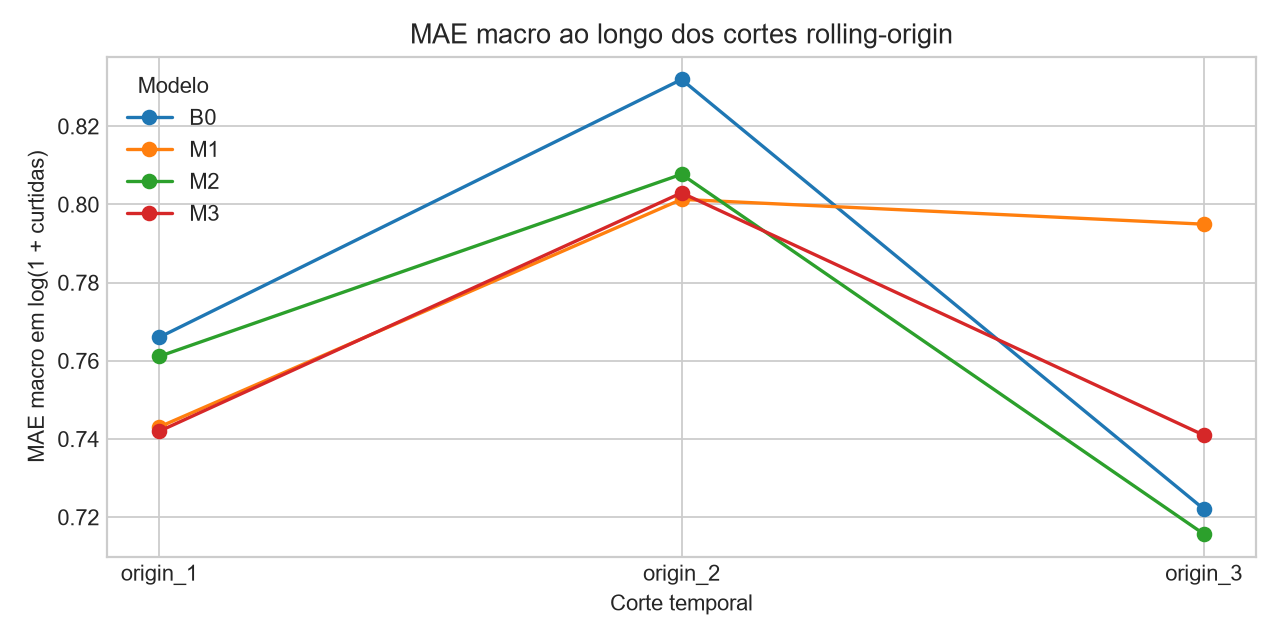

In [2]:
display(Image(filename=str(ARTIFACTS / 'figures' / '07_rolling_origin_mae_por_modelo.png')))